# Validation of PyGEM-WBM glacier contributions to river flows
Following data that was aggregated by Schaner et al. (2012), Azam et al. (2021), as well as other more recent studies
- For annual estimates, we assume months are equally weighted (i.e., we do not weight by days in the month).

In [1]:
import os

from tqdm import tqdm

from affine import Affine
import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import Patch
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FixedLocator, LogLocator, NullFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
from rasterstats import zonal_stats
import rioxarray
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from scipy.spatial import cKDTree
from shapely.geometry import Point
import xarray as xr

In [2]:
wbm_fp = 'NSLCT_historical_1980_2015_v4/monthly/'

In [3]:
def discharge_pgps_pg_years_avg(years, site_lat, site_lon):
    """Return average percent from glaciers and from glaciers and snow for years"""

    for nyear, year in enumerate(years):
    
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        discharge_yr = ds['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        if nyear == 0:
            discharge = discharge_yr
            discharge_pg = discharge_pg_yr
            discharge_ps = discharge_ps_yr
        else:
            discharge = np.concatenate((discharge, discharge_yr))
            discharge_pg = np.concatenate((discharge_pg, discharge_pg_yr))
            discharge_ps = np.concatenate((discharge_ps, discharge_ps_yr))
    
    discharge_pgps_perc = 100 * (discharge_pg.sum() + discharge_ps.sum()) / discharge.sum()
    discharge_pg_perc = 100 * discharge_pg.sum() / discharge.sum()

    print('Mean annual percent from glacier and snow:',  np.round(discharge_pgps_perc,1))
    print('Mean annual percent from glacier:',  np.round(discharge_pg_perc,1))

    return discharge_pgps_perc, discharge_pg_perc


def discharge_pgps_pg_months_avg(years, site_lat, site_lon, months, print_pgps=True):
    """Return average percent from glaciers and from glaciers and snow for years but only for select months"""
    
    for nyear, year in enumerate(years):
        
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        discharge_yr = ds_months['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds_months['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        if nyear == 0:
            discharge = discharge_yr
            discharge_pg = discharge_pg_yr
            discharge_ps = discharge_ps_yr
        else:
            discharge = np.concatenate((discharge, discharge_yr))
            discharge_pg = np.concatenate((discharge_pg, discharge_pg_yr))
            discharge_ps = np.concatenate((discharge_ps, discharge_ps_yr))
    
    discharge_pgps_perc = 100 * (discharge_pg.sum() + discharge_ps.sum()) / discharge.sum()
    discharge_pg_perc = 100 * discharge_pg.sum() / discharge.sum()

    if print_pgps:
        print('Mean', months, 'percent from glacier and snow:',  np.round(discharge_pgps_perc,1))
        
    print('Mean', months, 'percent from glacier:',  np.round(discharge_pg_perc,1))

    return discharge_pgps_perc, discharge_pg_perc

### Jain (2002) - Deoprayag, Ganga River, India
Assume 1990-2000 since time period not provided (only that it was a decade)

"It has also been reported that, on average <b>snow and glacier melt</b> contributes 28.7% of the average annual flow in the Ganga River at Deoprayag, whilst rainfall contributes the remaining flow"

78.598° E, 30.146° N

In [4]:
site_lon = 78.598
site_lat = 30.146
years = range(1990, 2000)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 26.9
Mean annual percent from glacier: 10.1


## Kumar et al. (2007) - Pandoh Dam, Beas River, India
"The results of the analysis show that the <b>snow- and glacier-melt</b> runoff contributes about 35% to the annual flow of the Beas River at Pandoh Dam."

In [5]:
site_lon = 77.0667
site_lat = 31.6709
years = range(1990, 2005)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 31.2
Mean annual percent from glacier: 8.1


## Singh et al. (1997) - Akhnoor, Chenab River, India

In [6]:
site_lon = 74.735489
site_lat = 32.896957
years = range(1983, 1993)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 52.6
Mean annual percent from glacier: 10.4


## Singh and Jain (2002) - Bhakra Dam, Satlug River, India

In [7]:
site_lon = 76.625  # (original - pixel misalignment)
site_lat = 31.4108
years = range(1987, 1997)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 54.2
Mean annual percent from glacier: 5.3


## Zhang et al. (2008) - Tuotuo River, China

In [8]:
site_lon = 92.5
site_lat = 34.15
years = range(1980, 2005)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 30.3
Mean annual percent from glacier: 3.0


## Mark and Seltzer - Yanamarey, Cordillera Blanca, Peru

In [9]:
# Glacier - Yanamarey
# site_lon = -77.3242
# site_lat = -9.7161

# Rio Santa terminus
site_lon = -78.634712 
site_lat = -8.965844

# # Lake Querococha
# site_lon = -77.3242
# site_lat = -9.7161
# years = range(1998, 2000)
years = range(1998, 2004)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 4.3
Mean annual percent from glacier: 4.3


## Bash et al. (2014) - Bow River, Alberta, Canada

In [10]:
site_lon = -114.05
site_lat = 51.05
years = range(2000, 2010)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 38.6
Mean annual percent from glacier: 3.8


In [11]:
site_lon = -114.05
site_lat = 51.05
years = range(2000, 2010)
months = [6,7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [6, 7, 8, 9] percent from glacier and snow: 39.7
Mean [6, 7, 8, 9] percent from glacier: 5.5


In [12]:
site_lon = -114.05
site_lat = 51.05
years = range(2000, 2010)
months_list = [[5],[6],[7],[8],[9]]

for months in months_list:
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months, print_pgps=False)

Mean [5] percent from glacier: 0.4
Mean [6] percent from glacier: 1.5
Mean [7] percent from glacier: 7.2
Mean [8] percent from glacier: 10.9
Mean [9] percent from glacier: 5.8


In [13]:
site_lon = -114.05
site_lat = 51.05
years = range(2000, 2010)
months_list = [[5],[6],[7],[8],[9]]

for nyear, year in enumerate(years):
    for months in months_list:
        # print('Month:', months)
        
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        discharge_yr = ds_months['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds_months['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        discharge = discharge_yr.values[0]
        discharge_pg = discharge_pg_yr.values[0]
        discharge_ps = discharge_ps_yr.values[0]
    
        discharge_pg_perc = 100 * discharge_pg / discharge

        print(year, months, 'percent from glacier:',  np.round(discharge_pg_perc,1))

2000 [5] percent from glacier: 0.3
2000 [6] percent from glacier: 0.5
2000 [7] percent from glacier: 4.9
2000 [8] percent from glacier: 8.0
2000 [9] percent from glacier: 4.1
2001 [5] percent from glacier: 0.3
2001 [6] percent from glacier: 0.9
2001 [7] percent from glacier: 7.5
2001 [8] percent from glacier: 14.5
2001 [9] percent from glacier: 15.6
2002 [5] percent from glacier: 0.4
2002 [6] percent from glacier: 1.6
2002 [7] percent from glacier: 6.9
2002 [8] percent from glacier: 9.7
2002 [9] percent from glacier: 3.4
2003 [5] percent from glacier: 0.3
2003 [6] percent from glacier: 1.9
2003 [7] percent from glacier: 8.6
2003 [8] percent from glacier: 17.9
2003 [9] percent from glacier: 11.8
2004 [5] percent from glacier: 0.6
2004 [6] percent from glacier: 1.6
2004 [7] percent from glacier: 7.5
2004 [8] percent from glacier: 10.0
2004 [9] percent from glacier: 4.6
2005 [5] percent from glacier: 0.4
2005 [6] percent from glacier: 1.3
2005 [7] percent from glacier: 5.1
2005 [8] percen

## Marshall etal (2011)

### North Saskatchewan River at Edmonton
Can't get the basins to line up

In [14]:
site_lon = -113.4855
site_lat = 52.5372
years = range(2000, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 18.1
Mean annual percent from glacier: 0.0


In [15]:
site_lon = -113.4855
site_lat = 52.5372
years = range(2000, 2008)
months = [6,7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [6, 7, 8, 9] percent from glacier and snow: 10.6
Mean [6, 7, 8, 9] percent from glacier: 0.0


## Chernos et al. (2020) - Athabasca River

In [16]:
site_lon = -117.5694
site_lat = 53.4242
years = range(1981, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 47.9
Mean annual percent from glacier: 4.3


In [17]:
site_lon = -117.5694
site_lat = 53.4242
# years = range(1985, 1996)
# years = range(1995, 2006)
years = range(2006, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 52.4
Mean annual percent from glacier: 4.9


In [18]:
site_lon = -117.5694
site_lat = 53.4242
years = range(1981, 2011)

months_list = [[6],[7],[8],[9]]

for months in months_list:
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months, print_pgps=False)

Mean [6] percent from glacier: 1.9
Mean [7] percent from glacier: 9.0
Mean [8] percent from glacier: 11.0
Mean [9] percent from glacier: 4.2


### Athabasca River at Jasper

In [19]:
site_lon = -118.05
site_lat = 52.91
# years = range(1985, 1996)
# years = range(1995, 2006)
years = range(2006, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 55.6
Mean annual percent from glacier: 7.8


## Neal et al. (2010)
### Alsek River

In [20]:
site_lon = -138.62
site_lat = 59.128
years = range(1980, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 79.1
Mean annual percent from glacier: 47.2


### Copper River

In [21]:
site_lon = -144.96
site_lat = 60.3886
years = range(1980, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 75.9
Mean annual percent from glacier: 37.1


### Susistna River

In [22]:
site_lon = -150.58
site_lat = 61.27
years = range(1980, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 60.8
Mean annual percent from glacier: 25.1


## Comeau et al. 2009 - lots in Canada
Odd definition of glacier wastage and glacier melt

In [23]:
# North Saskatchewan River, Edmonton
site_lon = 	-113.4909
site_lat = 53.5444
years = range(1980, 1999)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 34.2
Mean annual percent from glacier: 2.9


In [24]:
# Bow River, Calgary
site_lon = 	-114.06
site_lat = 51.05	
years = range(1980, 1999)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 37.4
Mean annual percent from glacier: 3.4


#### Months

In [25]:
# Mistaya River near Sask 
site_lon = -116.68917
site_lat = 51.88417
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 63.6
Mean [7, 8, 9] percent from glacier: 33.3


In [26]:
# North Sask River at Whirlpool Point
site_lon = -116.47083
site_lat = 52.001111
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 53.6
Mean [7, 8, 9] percent from glacier: 23.4


In [27]:
# Siffleur River
site_lon = -116.385
site_lat = 52.044	
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 53.6
Mean [7, 8, 9] percent from glacier: 23.4


In [28]:
# Ram River
site_lon = -115.4219
site_lat = 52.3683	
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 41.7
Mean [7, 8, 9] percent from glacier: 7.9


In [29]:
# North Sask River
site_lon = -116.725
site_lat = 51.9667	
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 63.6
Mean [7, 8, 9] percent from glacier: 33.3


In [30]:
# Bow River
site_lon = -116.18
site_lat = 51.42	
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 58.7
Mean [7, 8, 9] percent from glacier: 25.3


In [31]:
# Pipestone River
site_lon = -116.17495
site_lat = 51.43311		
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 58.7
Mean [7, 8, 9] percent from glacier: 25.3


In [32]:
# Johnston Creek
site_lon = -115.8544
site_lat = 51.2417	
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 55.5
Mean [7, 8, 9] percent from glacier: 21.2


In [33]:
# Bow River
site_lon = -115.5716
site_lat = 51.1724		
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 51.1
Mean [7, 8, 9] percent from glacier: 16.0


In [34]:
# Brewster River
site_lon = -115.66
site_lat = 51.09		
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 51.1
Mean [7, 8, 9] percent from glacier: 16.0


In [35]:
# Minnewanka
site_lon = -115.48611
site_lat = 51.23611	
years = range(1993, 2004)
months = [7,8,9] # July-Sept

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Mean [7, 8, 9] percent from glacier and snow: 47.0
Mean [7, 8, 9] percent from glacier: 13.2


## Jost et al. (2012) - Mica Dam, Canada
Glacier melt only is their study

In [36]:
site_lon = -118.5639
site_lat = 52.0778	
years = range(1980, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 61.6
Mean annual percent from glacier: 21.7


## Huss (2011) - Europe

#### Rhine River

In [37]:
# Rhine River
site_lon = 4.0806
site_lat = 51.9817	
years = range(1988, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 19.8
Mean [6] percent from glacier: 0.8
Month: [7]
Mean [7] percent from glacier and snow: 21.2
Mean [7] percent from glacier: 2.7
Month: [8]
Mean [8] percent from glacier and snow: 20.0
Mean [8] percent from glacier: 5.2
Month: [9]
Mean [9] percent from glacier and snow: 17.1
Mean [9] percent from glacier: 6.3
Month: [10]
Mean [10] percent from glacier and snow: 8.2
Mean [10] percent from glacier: 2.7


In [38]:
# Rhine River
site_lon = 4.0806
site_lat = 51.9817	
years = range(2004, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 19.0
Mean [6] percent from glacier: 1.0
Month: [7]
Mean [7] percent from glacier and snow: 19.8
Mean [7] percent from glacier: 3.1
Month: [8]
Mean [8] percent from glacier and snow: 17.7
Mean [8] percent from glacier: 5.3
Month: [9]
Mean [9] percent from glacier and snow: 13.5
Mean [9] percent from glacier: 5.1
Month: [10]
Mean [10] percent from glacier and snow: 8.3
Mean [10] percent from glacier: 3.1


In [39]:
# Rhine River
site_lon = 4.0806
site_lat = 51.9817	
years = range(2003, 2004)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    # print('Month:', months)

    for nyear, year in enumerate(years):
        
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        discharge_yr = ds_months['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds_months['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        discharge = discharge_yr.values[0]
        discharge_pg = discharge_pg_yr.values[0]
        discharge_ps = discharge_ps_yr.values[0]
    
    discharge_pg_perc = 100 * discharge_pg / discharge

    print('Mean', months, 'percent from glacier:',  np.round(discharge_pg_perc,1))

Mean [6] percent from glacier: 1.1
Mean [7] percent from glacier: 6.4
Mean [8] percent from glacier: 10.9
Mean [9] percent from glacier: 14.1
Mean [10] percent from glacier: 13.8


#### Rhone River

In [40]:
# Rhone River
site_lon = 4.8456
site_lat = 43.3308	
years = range(1988, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 29.0
Mean [6] percent from glacier: 2.1
Month: [7]
Mean [7] percent from glacier and snow: 35.5
Mean [7] percent from glacier: 6.3
Month: [8]
Mean [8] percent from glacier and snow: 32.0
Mean [8] percent from glacier: 10.1
Month: [9]
Mean [9] percent from glacier and snow: 26.3
Mean [9] percent from glacier: 10.4
Month: [10]
Mean [10] percent from glacier and snow: 7.5
Mean [10] percent from glacier: 2.3


In [41]:
# Rhone River
site_lon = 4.8456
site_lat = 43.3308	
years = range(2004, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 29.4
Mean [6] percent from glacier: 2.8
Month: [7]
Mean [7] percent from glacier and snow: 35.8
Mean [7] percent from glacier: 7.6
Month: [8]
Mean [8] percent from glacier and snow: 27.7
Mean [8] percent from glacier: 9.7
Month: [9]
Mean [9] percent from glacier and snow: 22.1
Mean [9] percent from glacier: 9.6
Month: [10]
Mean [10] percent from glacier and snow: 8.6
Mean [10] percent from glacier: 3.3


In [42]:
# Rhone River
site_lon = 4.8456
site_lat = 43.3308	
years = range(2003, 2004)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    # print('Month:', months)

    for nyear, year in enumerate(years):
        
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        discharge_yr = ds_months['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds_months['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        discharge = discharge_yr.values[0]
        discharge_pg = discharge_pg_yr.values[0]
        discharge_ps = discharge_ps_yr.values[0]
    
    discharge_pg_perc = 100 * discharge_pg / discharge

    print('Mean', months, 'percent from glacier:',  np.round(discharge_pg_perc,1))

Mean [6] percent from glacier: 5.7
Mean [7] percent from glacier: 13.4
Mean [8] percent from glacier: 20.5
Mean [9] percent from glacier: 26.0
Mean [10] percent from glacier: 3.4


#### Po River

In [43]:
# Po River
site_lon = 12.4319
site_lat = 44.9525	
years = range(1988, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 23.4
Mean [6] percent from glacier: 1.5
Month: [7]
Mean [7] percent from glacier and snow: 24.6
Mean [7] percent from glacier: 4.1
Month: [8]
Mean [8] percent from glacier and snow: 22.6
Mean [8] percent from glacier: 6.7
Month: [9]
Mean [9] percent from glacier and snow: 18.0
Mean [9] percent from glacier: 6.4
Month: [10]
Mean [10] percent from glacier and snow: 7.8
Mean [10] percent from glacier: 2.2


In [44]:
# Po River
site_lon = 12.4319
site_lat = 44.9525	
years = range(2004, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 22.9
Mean [6] percent from glacier: 2.2
Month: [7]
Mean [7] percent from glacier and snow: 26.1
Mean [7] percent from glacier: 5.5
Month: [8]
Mean [8] percent from glacier and snow: 23.4
Mean [8] percent from glacier: 8.8
Month: [9]
Mean [9] percent from glacier and snow: 16.9
Mean [9] percent from glacier: 7.3
Month: [10]
Mean [10] percent from glacier and snow: 8.8
Mean [10] percent from glacier: 3.2


In [45]:
# Po River
site_lon = 12.4319
site_lat = 44.9525	
years = range(2003, 2004)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    # print('Month:', months)

    for nyear, year in enumerate(years):
        
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        discharge_yr = ds_months['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds_months['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        discharge = discharge_yr.values[0]
        discharge_pg = discharge_pg_yr.values[0]
        discharge_ps = discharge_ps_yr.values[0]
    
    discharge_pg_perc = 100 * discharge_pg / discharge

    print('Mean', months, 'percent from glacier:',  np.round(discharge_pg_perc,1))

Mean [6] percent from glacier: 3.8
Mean [7] percent from glacier: 9.2
Mean [8] percent from glacier: 13.7
Mean [9] percent from glacier: 18.3
Mean [10] percent from glacier: 7.4


#### Danube River

In [46]:
# Danube River
site_lon = 28.73
site_lat = 45.22	
years = range(1988, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 26.8
Mean [6] percent from glacier: 0.0
Month: [7]
Mean [7] percent from glacier and snow: 22.3
Mean [7] percent from glacier: 0.1
Month: [8]
Mean [8] percent from glacier and snow: 18.9
Mean [8] percent from glacier: 0.4
Month: [9]
Mean [9] percent from glacier and snow: 15.3
Mean [9] percent from glacier: 1.0
Month: [10]
Mean [10] percent from glacier and snow: 10.5
Mean [10] percent from glacier: 1.2


In [47]:
# Danube River
site_lon = 28.73
site_lat = 45.22	
years = range(2004, 2009)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    print('Month:', months)
    discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_months_avg(years, site_lat, site_lon, months)

Month: [6]
Mean [6] percent from glacier and snow: 28.9
Mean [6] percent from glacier: 0.0
Month: [7]
Mean [7] percent from glacier and snow: 23.2
Mean [7] percent from glacier: 0.1
Month: [8]
Mean [8] percent from glacier and snow: 18.9
Mean [8] percent from glacier: 0.5
Month: [9]
Mean [9] percent from glacier and snow: 13.8
Mean [9] percent from glacier: 1.0
Month: [10]
Mean [10] percent from glacier and snow: 9.1
Mean [10] percent from glacier: 1.2


In [48]:
# Danube River
site_lon = 28.73
site_lat = 45.22	
years = range(2003, 2004)
months_list = [[6],[7],[8],[9],[10]]

for months in months_list:
    # print('Month:', months)

    for nyear, year in enumerate(years):
        
        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        discharge_yr = ds_months['discharge'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_pg_yr = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest')
        discharge_ps_yr = ds_months['discharge_m3s_ps'].sel(lat=site_lat, lon=site_lon, method='nearest')
    
        discharge = discharge_yr.values[0]
        discharge_pg = discharge_pg_yr.values[0]
        discharge_ps = discharge_ps_yr.values[0]
    
    discharge_pg_perc = 100 * discharge_pg / discharge

    print('Mean', months, 'percent from glacier:',  np.round(discharge_pg_perc,1))

Mean [6] percent from glacier: 0.0
Mean [7] percent from glacier: 0.2
Mean [8] percent from glacier: 0.7
Mean [9] percent from glacier: 1.6
Mean [10] percent from glacier: 2.6


## RIVER BASIN ANALYSIS - COMPARING HUSS (2011) with downstream glacier water compared to input

In [49]:
# Rhone River
site_lon = 4.8456
site_lat = 43.3308	

rivers_df = pd.read_csv('wbm_data/wbm_rivers/MERIT_plus_15min_v1_IDs_super.csv')
rhone_id = rivers_df.loc[rivers_df['Name']=='Rhone', 'ID'].values[0]
rhone_id

143

In [50]:
river_id_dict = {'Amu-Darya':3}
river_fn = 'wbm_data/wbm_rivers/MERIT_plus_15min_v1_IDs_wcrs-wibt.tif'

# river_names = ['Indus', 'Ganges', 'Copper', 'Alsek']
river_names = ['Rhone']

river_value_dict = {}

for river_name in river_names:
    if river_name in river_id_dict.keys():
        river_id = river_id_dict[river_name]
    else:
        river_id = rivers_df.loc[rivers_df['Name'] == river_name, 'ID'].values

    print(river_id)

    with rasterio.open(river_fn) as dataset:
        # Read the first band into a NumPy array
        river_array = dataset.read(1)
        transform = dataset.transform
        height, width = dataset.height, dataset.width
    
    # Create row/col index grids
    rows, cols = np.meshgrid(np.arange(height), np.arange(width), indexing='ij')
    
    # Convert pixel indices to coordinates
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    
    # Convert to arrays
    lon = np.array(xs)
    lat = np.array(ys)
    
    lons = lon[0,:]
    lats = lat[:,0]

    # River data
    river_array[river_array<0] = 0
    river_array[river_array!=river_id] = 0
    # river_array[np.isnan(q)] = 0

[143]


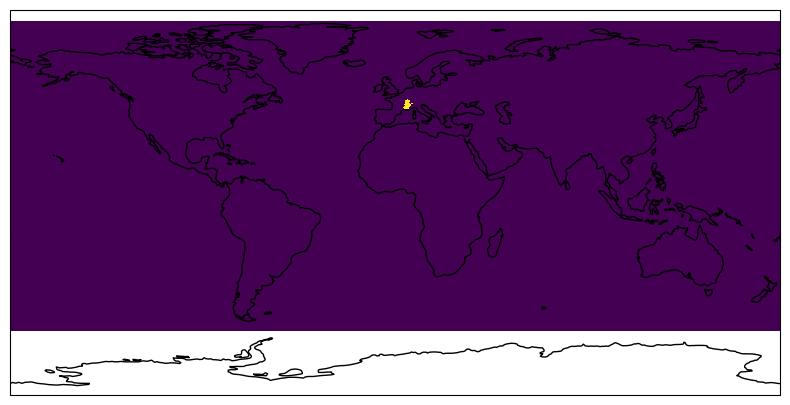

In [51]:

fig, ax = plt.subplots(
    figsize=(10, 5),
    subplot_kw={"projection": ccrs.PlateCarree()}  # nice global projection
)


im = ax.pcolormesh(lons, lats, river_array, transform=ccrs.PlateCarree(),
                       # cmap=cmap1, 
                       # norm=norm1, 
                       zorder=0)

ax.set_global()
# ax.set_extent([-5, 15, 40, 60], crs=ccrs.PlateCarree())
ax.coastlines()

plt.show()

In [52]:
years = range(2000, 2011)
months_list = [[6],[7],[8],[9],[10]]
# months_list = [[7]]

for months in months_list:
    print('Month:', months)

    for nyear, year in enumerate(years):

        ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
        ds_months = ds.sel(time=ds.time.dt.month.isin(months))
        glMelt_raw = ds_months.glMelt.values[0,:,:]
        
        # Flip array!
        glMelt = glMelt_raw[::-1,:]

        # Filter only to basin
        river_bool = np.zeros(river_array.shape)
        river_bool[river_array == river_id] = 1
        glMelt_basin = glMelt * river_bool
        glMelt_basin_sum = np.nansum(glMelt_basin)

        # Discharge at outlet of basin that's glaciers
        discharge_pg = ds_months['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest').values[0]

        print(np.round(discharge_pg / glMelt_basin_sum,2))

        # fig, ax = plt.subplots(
        #     figsize=(10, 5),
        #     subplot_kw={"projection": ccrs.PlateCarree()}  # nice global projection
        # )
        
        
        # im = ax.pcolormesh(lons, lats, glMelt_basin, transform=ccrs.PlateCarree(),
        #                        # cmap=cmap1, 
        #                        # norm=norm1, 
        #                        zorder=0)
        
        # # ax.set_global()
        # ax.set_extent([-5, 15, 40, 60], crs=ccrs.PlateCarree())
        # ax.coastlines()
        
        # plt.show()

Month: [6]
0.4
0.56
0.38
0.36
0.42
0.35
0.39
0.5
0.48
0.54
0.48
Month: [7]
0.87
0.55
0.66
0.64
0.58
0.61
0.46
0.64
0.59
0.55
0.52
Month: [8]
0.59
0.69
0.88
0.58
0.71
0.86
1.69
0.79
0.72
0.6
0.93
Month: [9]
1.33
16.85
3.46
2.05
1.07
0.93
0.59
2.48
2.62
1.34
2.28
Month: [10]
37.26
1.26
22.78
2155.92
15.43
7.96
4.19
10.11
7.48
26.34
41.62


#### Get the average that reaches over the year

In [53]:
years = range(2003, 2004)

for nyear, year in enumerate(years):

    ds = xr.open_dataset(wbm_fp + 'wbm_' + str(year) + '.nc')
    glMelt_raw = np.nansum(ds.glMelt.values, axis=0)
    
    # Flip array!
    glMelt = glMelt_raw[::-1,:]

    # Filter only to basin
    river_bool = np.zeros(river_array.shape)
    river_bool[river_array == river_id] = 1
    glMelt_basin = glMelt * river_bool
    glMelt_basin_sum = np.nansum(glMelt_basin)

    # Discharge at outlet of basin that's glaciers
    discharge_pg = np.nansum(ds['discharge_m3s_pg'].sel(lat=site_lat, lon=site_lon, method='nearest').values)

    print(np.round(discharge_pg / glMelt_basin_sum,2))

    # fig, ax = plt.subplots(
    #     figsize=(10, 5),
    #     subplot_kw={"projection": ccrs.PlateCarree()}  # nice global projection
    # )
    
    
    # im = ax.pcolormesh(lons, lats, glMelt, transform=ccrs.PlateCarree(),
    #                        # cmap=cmap1, 
    #                        # norm=norm1, 
    #                        zorder=0)
    
    # # ax.set_global()
    # ax.set_extent([-5, 15, 40, 60], crs=ccrs.PlateCarree())
    # ax.coastlines()
    
    # plt.show()

0.83


## Lutz et al. (2014) - Table S2

In [54]:
# Bhakra Dam, Satlug River, India
site_lon = 76.625  # (original - pixel misalignment)
site_lat = 31.4108
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 54.1
Mean annual percent from glacier: 7.6


In [55]:
# Langtang
site_lon = 85.5275
site_lat = 28.214	
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 22.6
Mean annual percent from glacier: 10.0


In [56]:
# Langtang
site_lon = 85.5275
site_lat = 28.214	
years = range(2001, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 21.8
Mean annual percent from glacier: 10.2


In [57]:
# Dudh Koshi (Racoviteanu et al. 2013)
site_lon = 86.65
site_lat = 27.26	
years = range(1988, 2007)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 10.8
Mean annual percent from glacier: 5.6


In [58]:
# Dudh Koshi (Lutz et al. 2014)
site_lon = 86.65
site_lat = 27.26	
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 10.4
Mean annual percent from glacier: 5.5


In [59]:
# Indus, Besham Qila (Lutz et al. 2014)
site_lon = 72.87
site_lat = 34.92	
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 66.8
Mean annual percent from glacier: 14.8


In [60]:
# Indus, Besham Qila (Mukhopadhyay and Khan 2014)
site_lon = 72.87
site_lat = 34.92	
years = range(1980, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 67.0
Mean annual percent from glacier: 12.1


In [61]:
# Hunza, Dainyor Bridge (Mukhopadhyay and Khan 2014)
site_lon = 74.37
site_lat = 35.93
years = range(1980, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 77.0
Mean annual percent from glacier: 20.7


In [62]:
# Hunza, Dainyor Bridge (Shrestha and Nepal 2019)
site_lon = 74.37
site_lat = 35.93
years = range(2000, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 76.8
Mean annual percent from glacier: 23.6


In [63]:
# Hunza, Dainyor Bridge (Shrestha and Nepal 2019)
site_lon = 74.37
site_lat = 35.93
years = range(2002, 2005)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 77.6
Mean annual percent from glacier: 20.9


In [64]:
# Hunza, Dainyor Bridge (Lutz et al. 2014)
site_lon = 74.37
site_lat = 35.93
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 76.5
Mean annual percent from glacier: 23.6


In [65]:
# Indus, Kachura (Mukhopadhyay and Khan 2014)
site_lon = 75.43
site_lat = 35.5
years = range(1980, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 85.4
Mean annual percent from glacier: 36.2


In [66]:
# Upper Indus (Lutz et al. 2014; Azam et al. 2021)
site_lon = 72.7
site_lat = 34.09	
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 63.3
Mean annual percent from glacier: 14.0


In [67]:
# Upper Indus (Immerzeel et al. 2009; Azam et al. 2021)
site_lon = 72.7
site_lat = 34.09	
years = range(2001, 2006)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 64.6
Mean annual percent from glacier: 13.4


In [68]:
# Upper Indus (Mukhopadhyay and Khan 2014; Azam et al. 2021)
site_lon = 72.7
site_lat = 34.09	
years = range(1980, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 63.0
Mean annual percent from glacier: 11.4


In [69]:
# Shigar (Indus) (Soncini et al. 2015; Azam et al. 2021)
site_lon = 75.75
site_lat = 35.37	
years = range(1985, 1996)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 69.9
Mean annual percent from glacier: 7.6


In [70]:
# Beas (Indus) (Kumar et al. 2007; Azam et al. 2021)
site_lon = 77.0669
site_lat = 31.6714
years = range(1990, 2005)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 31.2
Mean annual percent from glacier: 8.1


In [71]:
# Ghaghara River outlet (Lutz et al. 2014) - Upper Ganges River # REALLY NOT GOOD SITING THOUGH - IT'S UNKNOWN
site_lon = 84.67
site_lat = 25.75
years = range(1998, 2008)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 8.7
Mean annual percent from glacier: 2.7


In [72]:
# Trishuli, Ganges River (Kayastha et al. 2020)
site_lon = 84.422
site_lat = 27.7713
years = range(2007, 2014)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 15.0
Mean annual percent from glacier: 6.2


In [73]:
# Marsyangdi, Ganges River (Kayastha et al. 2020)
site_lon = 84.5592
site_lat = 27.8581
years = range(2004, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 17.0
Mean annual percent from glacier: 7.2


In [74]:
# Tamor, Ganges River (Kayastha et al. 2020)
# site_lon = 87.1583
# site_lat = 26.9131
site_lon = 87.7116
site_lat = 27.16
years = range(2000, 2011)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 13.6
Mean annual percent from glacier: 6.9


In [75]:
# Dudh Koshi, Ganges River (Nepal et al. 2014)
site_lon = 86.4333
site_lat = 27.1494
years = range(1986, 1998)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 9.8
Mean annual percent from glacier: 3.5


## Maipo River

In [76]:
# Maipo River (Ayala et al. 2020)
site_lon = -70.3794
site_lat = -33.5975
years = range(1980, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 74.4
Mean annual percent from glacier: 8.3


In [77]:
# Maipo River (McCarthy et al. 2022)
site_lon = -70.3794
site_lat = -33.5975
years = range(2000, 2016)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 75.0
Mean annual percent from glacier: 10.2


## La Paz, Bolivia (Soruco et al. 2015)

In [78]:
site_lon = -68.12
site_lat = -16.5
years = range(1980, 2007)

discharge_pgps_perc, discharge_pg_perc = discharge_pgps_pg_years_avg(years, site_lat, site_lon)

Mean annual percent from glacier and snow: 2.6
Mean annual percent from glacier: 2.5
